#**Project Title**

##**FBI Time Series Forecasting**


#**Project Summary**

This project focuses on forecasting crime incident counts using historical FBI crime data.
The dataset contains information such as YEAR, MONTH, and TYPE of crime. Since the target
is time-dependent, a time series forecasting approach is used.

The main goal is to aggregate incidents month-wise for each crime type and predict future
incident counts for the test dataset. A simple SARIMA-based forecasting model is used
because it can capture trend and seasonal patterns in monthly data.

The workflow includes:
1. Loading train and test datasets
2. Data cleaning and preprocessing
3. Monthly aggregation of crime incidents
4. Exploratory Data Analysis
5. Time series modeling using SARIMA
6. Generating predictions in submission format

This approach is simple, explainable, and suitable for implementation in Google Colab.


#**GitHub Link**
**bold text**
https://github.com/Vidya-imp

#**Problem Statement**

The objective of this project is to forecast the number of crime incidents for future months
based on historical FBI crime records. Using the given train dataset, the system learns
patterns in monthly crime occurrences for each crime type and predicts the incident counts
for the test dataset.


#**Define Your Business Objective**

The business objective is to build a forecasting system that helps understand future crime
trends. This can support planning, monitoring, and decision-making by identifying which
crime categories may increase or decrease over time.


Let's Begin !



#**1. Know Your Data**

**Import Libraries**

In [2]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error

**Dataset Loading**

In [4]:
# Load Dataset
train_df = pd.read_excel("/content/Train.xlsx")
test_df = pd.read_csv("/content/Test (2).csv")

**Dataset First View**

In [5]:
# Dataset First Look
train_df.head()

,TYPE,HUNDRED_BLOCK,NEIGHBOURHOOD,X,Y,Latitude,Longitude,HOUR,MINUTE,YEAR,MONTH,DAY,Date
0,Other Theft,9XX TERMINAL AVE,Strathcona,493906.5,5457452.47,49.269802,-123.083763,16.0,15.0,1999,5,12,1999-05-12
1,Other Theft,9XX TERMINAL AVE,Strathcona,493906.5,5457452.47,49.269802,-123.083763,15.0,20.0,1999,5,7,1999-05-07
2,Other Theft,9XX TERMINAL AVE,Strathcona,493906.5,5457452.47,49.269802,-123.083763,16.0,40.0,1999,4,23,1999-04-23
3,Other Theft,9XX TERMINAL AVE,Strathcona,493906.5,5457452.47,49.269802,-123.083763,11.0,15.0,1999,4,20,1999-04-20
4,Other Theft,9XX TERMINAL AVE,Strathcona,493906.5,5457452.47,49.269802,-123.083763,17.0,45.0,1999,4,12,1999-04-12


In [6]:
test_df.head()

,YEAR,MONTH,TYPE,Incident_Counts
0,2013,6,Vehicle Collision or Pedestrian Struck (with I...,NaN
1,2013,6,Theft of Vehicle,NaN
2,2013,6,Theft of Bicycle,NaN
3,2013,6,Theft from Vehicle,NaN
4,2013,6,Other Theft,NaN


**Dataset Rows & Columns Count**

In [7]:
# Dataset Rows & Columns count
print("Train Shape:", train_df.shape)
print("Test Shape :", test_df.shape)

Train Shape: (474565, 13)
Test Shape : (162, 4)


**Dataset Information**

In [8]:
# Dataset Info
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 474565 entries, 0 to 474564
Data columns (total 13 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   TYPE           474565 non-null  object        
 1   HUNDRED_BLOCK  474552 non-null  object        
 2   NEIGHBOURHOOD  423074 non-null  object        
 3   X              474565 non-null  float64       
 4   Y              474565 non-null  float64       
 5   Latitude       474565 non-null  float64       
 6   Longitude      474565 non-null  float64       
 7   HOUR           425200 non-null  float64       
 8   MINUTE         425200 non-null  float64       
 9   YEAR           474565 non-null  int64         
 10  MONTH          474565 non-null  int64         
 11  DAY            474565 non-null  int64         
 12  Date           474565 non-null  datetime64[ns]
dtypes: datetime64[ns](1), float64(6), int64(3), object(3)
memory usage: 47.1+ MB


**Duplicate Values**

In [9]:
# Dataset Duplicate Value Count
print("Duplicate rows in train:", train_df.duplicated().sum())
print("Duplicate rows in test :", test_df.duplicated().sum())

Duplicate rows in train: 44618
Duplicate rows in test : 0


**Missing Values**

In [10]:
# Missing Values/Null Values Count
train_df.isnull().sum()

,0
TYPE,0
HUNDRED_BLOCK,13
NEIGHBOURHOOD,51491
X,0
Y,0
Latitude,0
Longitude,0
HOUR,49365
MINUTE,49365
YEAR,0


In [11]:
test_df.isnull().sum()

,0
YEAR,0
MONTH,0
TYPE,0
Incident_Counts,162


#**2. Understanding Your Variables**



**Data Columns**

In [12]:
print("Train Columns:", train_df.columns.tolist())
print("Test Columns :", test_df.columns.tolist())

Train Columns: ['TYPE', 'HUNDRED_BLOCK', 'NEIGHBOURHOOD', 'X', 'Y', 'Latitude', 'Longitude', 'HOUR', 'MINUTE', 'YEAR', 'MONTH', 'DAY', 'Date']
Test Columns : ['YEAR', 'MONTH', 'TYPE', 'Incident_Counts']


**Data Preprocessing**

In [13]:
# Convert YEAR and MONTH into integer format
train_df["YEAR"] = train_df["YEAR"].astype(int)
train_df["MONTH"] = train_df["MONTH"].astype(int)

test_df["YEAR"] = test_df["YEAR"].astype(int)
test_df["MONTH"] = test_df["MONTH"].astype(int)

# Create Date column
train_df["Date"] = pd.to_datetime(
    train_df["YEAR"].astype(str) + "-" + train_df["MONTH"].astype(str) + "-01"
)

test_df["Date"] = pd.to_datetime(
    test_df["YEAR"].astype(str) + "-" + test_df["MONTH"].astype(str) + "-01"
)

train_df.head()

,TYPE,HUNDRED_BLOCK,NEIGHBOURHOOD,X,Y,Latitude,Longitude,HOUR,MINUTE,YEAR,MONTH,DAY,Date
0,Other Theft,9XX TERMINAL AVE,Strathcona,493906.5,5457452.47,49.269802,-123.083763,16.0,15.0,1999,5,12,1999-05-01
1,Other Theft,9XX TERMINAL AVE,Strathcona,493906.5,5457452.47,49.269802,-123.083763,15.0,20.0,1999,5,7,1999-05-01
2,Other Theft,9XX TERMINAL AVE,Strathcona,493906.5,5457452.47,49.269802,-123.083763,16.0,40.0,1999,4,23,1999-04-01
3,Other Theft,9XX TERMINAL AVE,Strathcona,493906.5,5457452.47,49.269802,-123.083763,11.0,15.0,1999,4,20,1999-04-01
4,Other Theft,9XX TERMINAL AVE,Strathcona,493906.5,5457452.47,49.269802,-123.083763,17.0,45.0,1999,4,12,1999-04-01


#**3. Data Wrangling**


**Aggregate Monthly Incident Counts**

In [14]:
# Since each row represents one record, count incidents by month and crime type
monthly_counts = (
    train_df.groupby(["Date", "TYPE"])
    .size()
    .reset_index(name="Incident_Counts")
)

monthly_counts.head()

,Date,TYPE,Incident_Counts
0,1999-01-01,Break and Enter Commercial,303
1,1999-01-01,Break and Enter Residential/Other,644
2,1999-01-01,Mischief,551
3,1999-01-01,Offence Against a Person,338
4,1999-01-01,Other Theft,247


**Create Complete Monthly Time Index**

In [15]:
all_types = monthly_counts["TYPE"].unique()
full_dates = pd.date_range(
    start=monthly_counts["Date"].min(),
    end=monthly_counts["Date"].max(),
    freq="MS"
)

full_index = pd.MultiIndex.from_product(
    [full_dates, all_types],
    names=["Date", "TYPE"]
)

monthly_counts = (
    monthly_counts.set_index(["Date", "TYPE"])
    .reindex(full_index, fill_value=0)
    .reset_index()
)

monthly_counts.head()

,Date,TYPE,Incident_Counts
0,1999-01-01,Break and Enter Commercial,303
1,1999-01-01,Break and Enter Residential/Other,644
2,1999-01-01,Mischief,551
3,1999-01-01,Offence Against a Person,338
4,1999-01-01,Other Theft,247


#**4. Data Vizualization, Storytelling & Experimenting with charts**


**Chart 1: Crime Type Distribution**


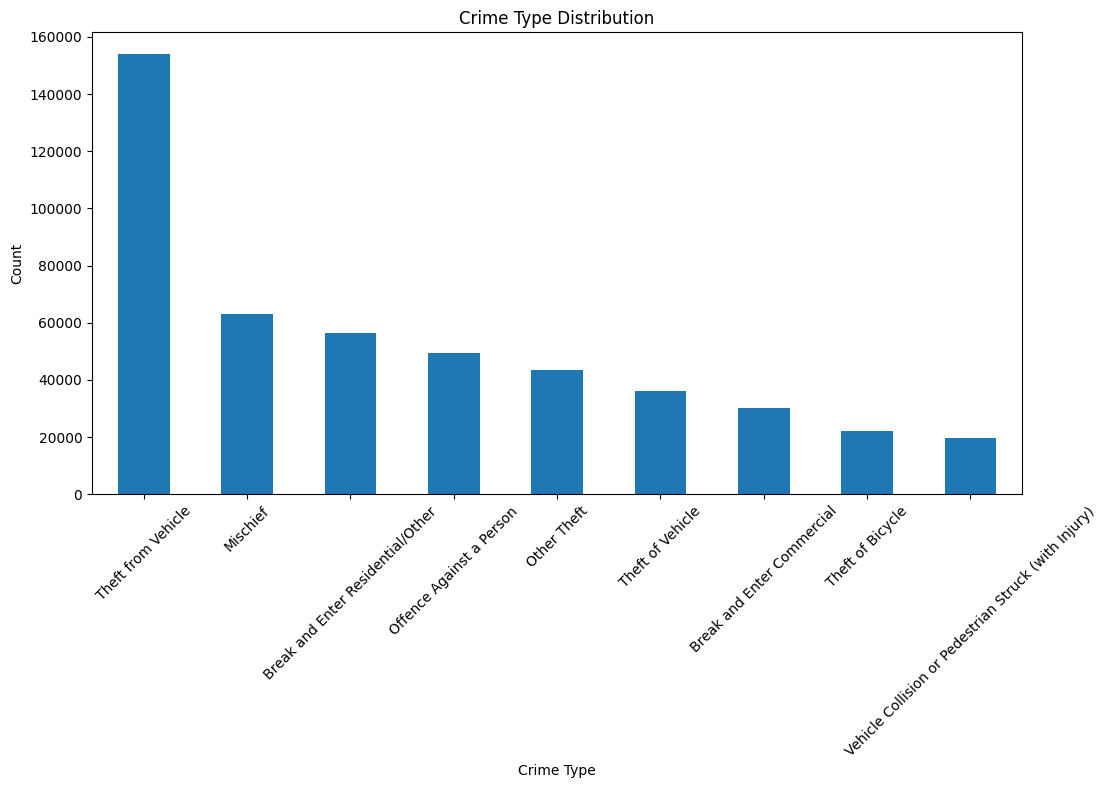

In [16]:
# Chart - 1 visualization code
plt.figure(figsize=(12,6))
train_df["TYPE"].value_counts().plot(kind="bar")
plt.title("Crime Type Distribution")
plt.xlabel("Crime Type")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

**Why did you pick the specific chart?**

Bar chart is used because it clearly shows the frequency of each crime category.
It helps compare different crime types easily.


**What is/are the insight(s) found from the chart?**

The chart shows which crime categories appear most frequently in the dataset.
This helps identify dominant crime types.


**Chart 2: Monthly Total Incidents**

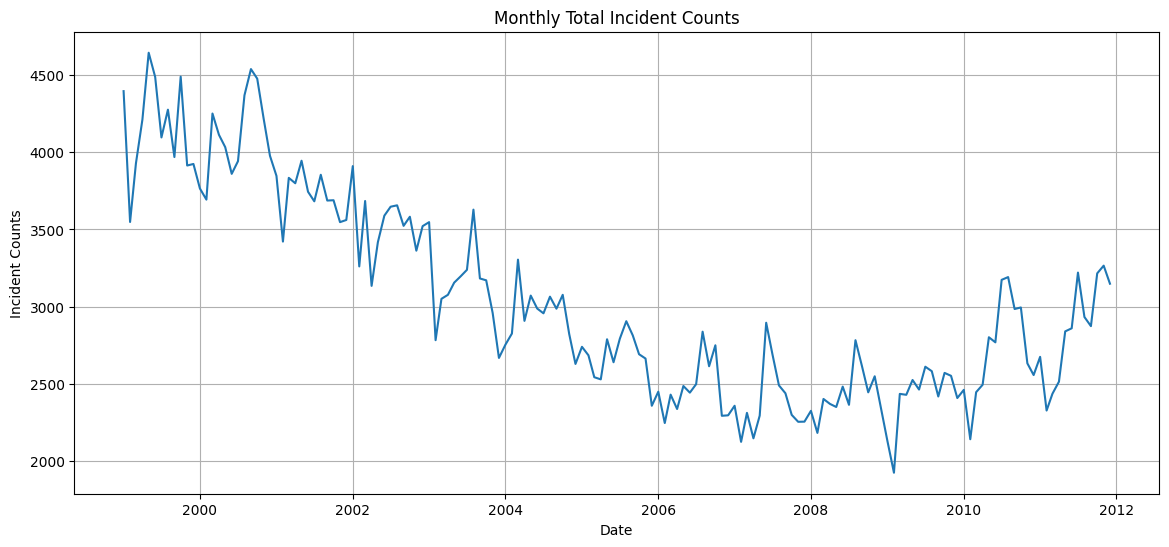

In [17]:
monthly_total = monthly_counts.groupby("Date")["Incident_Counts"].sum()

plt.figure(figsize=(14,6))
plt.plot(monthly_total.index, monthly_total.values)
plt.title("Monthly Total Incident Counts")
plt.xlabel("Date")
plt.ylabel("Incident Counts")
plt.grid(True)
plt.show()

**Why did you pick the specific chart?**

A line chart is best for time series data because it shows changes over time clearly.


**What is/are the insight(s) found from the chart?**

This chart helps identify overall trend, fluctuations, and possible seasonality
in monthly crime incidents.


**Chart 3: Top Crime Types Over Time**

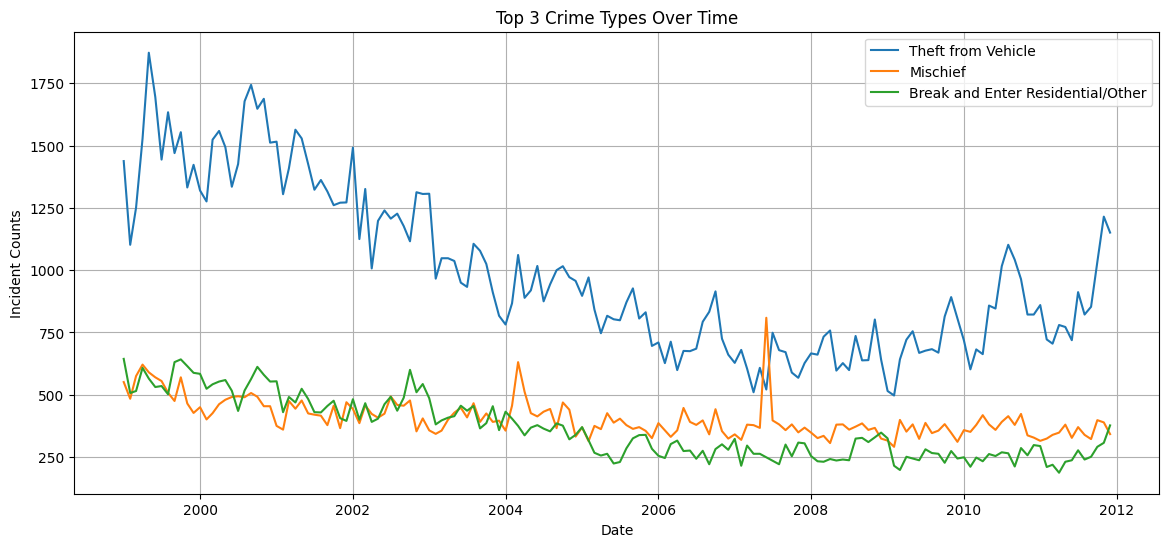

In [18]:
top_types = train_df["TYPE"].value_counts().head(3).index

plt.figure(figsize=(14,6))
for crime_type in top_types:
    temp = monthly_counts[monthly_counts["TYPE"] == crime_type]
    plt.plot(temp["Date"], temp["Incident_Counts"], label=crime_type)

plt.title("Top 3 Crime Types Over Time")
plt.xlabel("Date")
plt.ylabel("Incident Counts")
plt.legend()
plt.grid(True)
plt.show()

**What is/are the insight(s) found from the chart?**

This chart shows how the major crime categories behave month by month.
It helps compare trends between the top crime types.


#**5. Feature Engineering & Data Pre-processing**
No complex feature engineering is required for this simple time series model.
 Main features used:
 1. Date
 2. TYPE
 3. Incident_Counts (target)

#**6. ML Model Implementation**


**Create Forecast Function**

In [19]:
def forecast_for_type(type_name, train_data, future_dates):
    """
    Fits SARIMA model for one crime type and predicts future months.
    """
    ts = train_data[train_data["TYPE"] == type_name][["Date", "Incident_Counts"]].copy()
    ts = ts.sort_values("Date")
    ts = ts.set_index("Date").asfreq("MS")
    ts["Incident_Counts"] = ts["Incident_Counts"].fillna(0)

    # fallback if less data
    if len(ts) < 24:
        mean_val = max(0, int(round(ts["Incident_Counts"].mean())))
        return [mean_val] * len(future_dates)

    try:
        model = SARIMAX(
            ts["Incident_Counts"],
            order=(1,1,1),
            seasonal_order=(1,1,1,12),
            enforce_stationarity=False,
            enforce_invertibility=False
        )
        fitted_model = model.fit(disp=False)
        forecast = fitted_model.forecast(steps=len(future_dates))
        forecast = np.maximum(0, np.round(forecast)).astype(int)
        return forecast.tolist()

    except:
        mean_val = max(0, int(round(ts["Incident_Counts"].mean())))
        return [mean_val] * len(future_dates)

**Model Training and Prediction**

In [20]:
predictions = []

for crime_type in all_types:
    test_subset = test_df[test_df["TYPE"] == crime_type].copy()
    test_subset = test_subset.sort_values("Date")

    future_dates = test_subset["Date"].tolist()
    preds = forecast_for_type(crime_type, monthly_counts, future_dates)

    test_subset["Incident_Counts"] = preds
    predictions.append(test_subset)

final_pred_df = pd.concat(predictions, ignore_index=True)
final_pred_df.head()

,YEAR,MONTH,TYPE,Incident_Counts,Date
0,2012,1,Break and Enter Commercial,219,2012-01-01
1,2012,2,Break and Enter Commercial,191,2012-02-01
2,2012,3,Break and Enter Commercial,215,2012-03-01
3,2012,4,Break and Enter Commercial,198,2012-04-01
4,2012,5,Break and Enter Commercial,202,2012-05-01


**Final Submission Format**

In [22]:
submission_df = final_pred_df[["YEAR", "MONTH", "TYPE", "Incident_Counts"]]
submission_df.head()

,YEAR,MONTH,TYPE,Incident_Counts
0,2012,1,Break and Enter Commercial,219
1,2012,2,Break and Enter Commercial,191
2,2012,3,Break and Enter Commercial,215
3,2012,4,Break and Enter Commercial,198
4,2012,5,Break and Enter Commercial,202


#**7. Model Evaluation**

Since the test file usually does not contain actual target values, proper evaluation on test data is not possible directly. So we can do a simple validation split from train.

**Train-Validation Split**

In [23]:
# Simple validation using last 6 months for one crime type example
sample_type = all_types[0]

sample_data = monthly_counts[monthly_counts["TYPE"] == sample_type].copy()
sample_data = sample_data.sort_values("Date").set_index("Date")

train_part = sample_data.iloc[:-6]
valid_part = sample_data.iloc[-6:]

model = SARIMAX(
    train_part["Incident_Counts"],
    order=(1,1,1),
    seasonal_order=(1,1,1,12),
    enforce_stationarity=False,
    enforce_invertibility=False
)
fitted_model = model.fit(disp=False)

pred_valid = fitted_model.forecast(steps=len(valid_part))
pred_valid = np.maximum(0, np.round(pred_valid)).astype(int)

mae = mean_absolute_error(valid_part["Incident_Counts"], pred_valid)
rmse = np.sqrt(mean_squared_error(valid_part["Incident_Counts"], pred_valid))

print("Validation MAE :", mae)
print("Validation RMSE:", rmse)

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


Validation MAE : 25.166666666666668
Validation RMSE: 29.08321394435858


**Actual vs Predicted Plot**

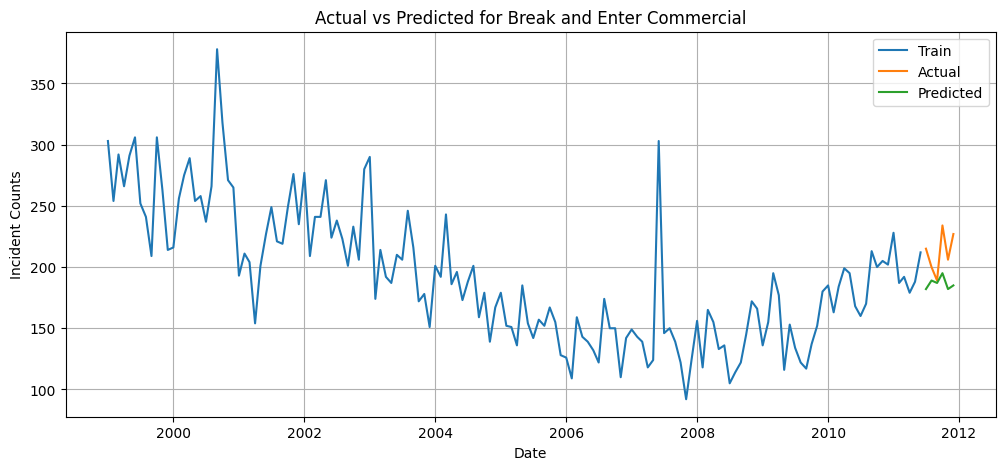

In [24]:
plt.figure(figsize=(12,5))
plt.plot(train_part.index, train_part["Incident_Counts"], label="Train")
plt.plot(valid_part.index, valid_part["Incident_Counts"], label="Actual")
plt.plot(valid_part.index, pred_valid, label="Predicted")
plt.title(f"Actual vs Predicted for {sample_type}")
plt.xlabel("Date")
plt.ylabel("Incident Counts")
plt.legend()
plt.grid(True)
plt.show()

#**8. Conclusion**

In this project, a simple time series forecasting model was built to predict future
crime incident counts. The data was aggregated month-wise for each crime type, and
a SARIMA model was trained separately for each category.

The model is easy to understand and suitable for forecasting monthly trends.
It can help identify future crime patterns and support planning and analysis.


#**9. Save Submission File**

In [25]:
submission_df.to_csv("/content/submission.csv", index=False)
print("submission.csv saved successfully")

submission.csv saved successfully


#**10. Download Submission File in Colab**

In [26]:
from google.colab import files
files.download("/content/submission.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>